# 31. Microsoft GraphRAG (Global Search)

Detect communities in the entity graph, summarise each, and answer global questions with map-reduce.

[![X](https://img.shields.io/badge/X-000000?style=for-the-badge&logo=x&logoColor=white)](https://x.com/techwith_ram) [![GitHub](https://img.shields.io/badge/GitHub-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/Ramakm) [![LinkedIn](https://img.shields.io/badge/LinkedIn-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/ramakrushnamohapatra/) [![Instagram](https://img.shields.io/badge/Instagram-E4405F?style=for-the-badge&logo=instagram&logoColor=white)](https://instagram.com/techwith.ram) [![Medium](https://img.shields.io/badge/Medium-000000?style=for-the-badge&logo=medium&logoColor=white)](https://medium.com/@techwithram)

## Why this matters

Vector RAG answers **local** questions (a fact in one chunk) but fails on **global** ones: *'What are the main themes of this corpus?'* - no single chunk contains the answer. **Microsoft GraphRAG** builds an entity graph, detects **communities** (clusters of closely related entities), writes a **report** for each, and answers global questions with **map-reduce** over those reports.

## How it works

1. Extract entities/relations -> graph
2. Detect communities (Leiden in the paper; Louvain here)
3. LLM writes a report per community
4. **Map:** each report answers the question and rates its relevance
5. **Reduce:** combine the best partial answers into a final answer

```text
 graph --> communities C1..Cn --> report R1..Rn
 global question --> [map: each Ri answers + score] --> keep high scores --> [reduce] --> final answer
```

## Prerequisites

Needs a running Ollama server (`ollama serve`) with `llama3.2` pulled, plus the shared helpers in `../common.py`.

**Extra requirements for this notebook:** `pip install networkx`

## Setup

Load the handbook, split it into ~500-character chunks (50 overlap) and index them. Every notebook starts from this same baseline so results are comparable.

In [1]:
import sys
sys.path.insert(0, "..")  # makes common.py importable
from common import *

text = load_text()
chunks = chunk_text(text, size=500, overlap=50)
store = build_store(chunks)
print(f"{len(chunks)} chunks indexed")

W1028 11:07:22.013000 9390 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


19 chunks indexed


In [2]:
import networkx as nx

G = nx.Graph()
for i, chunk in enumerate(chunks):
    for s, r, o in extract_triples(chunk):
        G.add_edge(s, o, relation=r)
print(G.number_of_nodes(), "entities,", G.number_of_edges(), "edges")

139 entities, 106 edges


## Community detection
Microsoft uses Leiden; networkx ships Louvain, which behaves similarly for this demo.

In [3]:
communities = nx.community.louvain_communities(G, seed=42)
communities = [c for c in communities if len(c) >= 3]
print(len(communities), "communities")

12 communities


## Community reports
Each community's facts are summarised once, at index time.

In [4]:
reports = []
for c in communities:
    facts = [f"{u} {d['relation']} {v}" for u, v, d in G.subgraph(c).edges(data=True)]
    reports.append(llm("Write a 2-sentence report describing the theme of these facts:\n" + "\n".join(facts)))
for r in reports[:3]: print("-", r)

- The theme of these facts appears to be the capabilities and features of a language model, specifically its ability to process and generate human-like text based on input queries or prompts. The model's functionality encompasses various aspects such as vector mapping, dimension production, reranking, and evidence checking, highlighting its sophisticated nature and versatility in producing coherent responses.
- The theme of this set of facts appears to be related to vectors and their use in data storage and retrieval, specifically focusing on the concept of similarity between vectors. The common thread among these facts is that they all relate to how vectors are used to measure and compare similarities between objects or data points in a database.
- The common thread among these facts is that they all relate to cloud-based services, specifically those used for vector search and machine learning applications. The fact that each service (Milvus, Qdrant, and Weaviate) has a "service runs"

## Global search = map-reduce
**Map:** each report answers the question with a helpfulness score. **Reduce:** combine the best partial answers.

In [5]:
def global_search(query):
    partials = []
    for rep in reports:
        out = llm_json(f'Using only this report, answer the question and rate relevance 0-10. Reply as JSON {{"answer": str, "score": int}}.\n\nReport: {rep}\n\nQuestion: {query}')
        if isinstance(out, dict) and out.get("score", 0) >= 5:
            partials.append(out["answer"])
    return llm("Combine these partial answers into one coherent answer:\n- " + "\n- ".join(partials)) if partials else "No relevant communities."

print(global_search("What are the main themes of this handbook?"))

This handbook appears to focus on the intersection of artificial intelligence, machine learning, and information systems, particularly in the context of search ranking algorithms and knowledge representation. The main theme revolves around the use of hybrid search as a common underlying component in various search ranking algorithms.

The handbook delves into the capabilities and features of language models, which are essential for understanding the role of vectors in data storage and retrieval. Vectors play a crucial role in determining similarity between documents or entities, enabling efficient information retrieval and generation. The concept of vector search is particularly relevant in machine learning applications, such as autonomous agents and OLLAMA algorithms.

The relationship between retrieval and generation in information systems is also explored, highlighting the importance of optimizing formats for better performance. This includes skill development, pedagogical approache

## Inspect the communities

In [6]:
for i, c in enumerate(communities[:5]):
    print(f"community {i} ({len(c)} entities): {sorted(c)[:8]}")
    print("   report:", reports[i][:200], "\n")

community 0 (16 entities): ['conversational', 'dimensions', 'evidence', 'from', 'good', 'ignore', 'model', 'popular']
   report: The theme of these facts appears to be the capabilities and features of a language model, specifically its ability to process and generate human-like text based on input queries or prompts. The model' 

community 1 (8 entities): ['cosine', 'dimension', 'distance', 'inaccurate', 'search', 'similarity', 'store', 'vector']
   report: The theme of this set of facts appears to be related to vectors and their use in data storage and retrieval, specifically focusing on the concept of similarity between vectors. The common thread among 

community 2 (4 entities): ['milvus', 'qdrant', 'service', 'weaviate']
   report: The common thread among these facts is that they all relate to cloud-based services, specifically those used for vector search and machine learning applications. The fact that each service (Milvus, Qd 

community 3 (6 entities): ['1 divided by (60 plus r

## Visualise communities by colour

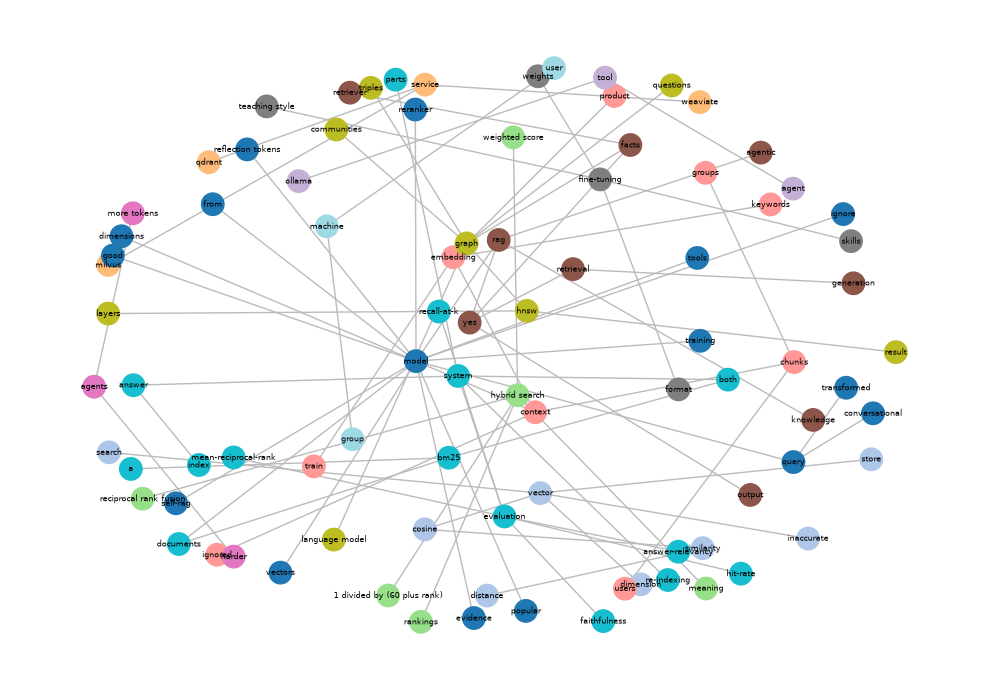

In [7]:
import matplotlib.pyplot as plt
colors = {}
for i, c in enumerate(communities):
    for n in c: colors[n] = i
plt.figure(figsize=(10, 7))
sub = G.subgraph([n for n in G if n in colors])
pos = nx.spring_layout(sub, seed=5, k=0.8)
nx.draw_networkx(sub, pos, node_color=[colors[n] for n in sub], cmap="tab20", node_size=260, font_size=6, edge_color="#bbb")
plt.axis("off"); plt.tight_layout(); plt.show()

## Local vs global questions
Compare vector RAG (good at local) with global search (good at themes).

In [8]:
global_q = "What are the main themes and topics covered across the whole handbook?"
print("VECTOR RAG (top-3 chunks):\n", rag(global_q, store, 3)[0], "\n")
print("GLOBAL SEARCH (community reports):\n", global_search(global_q))

VECTOR RAG (top-3 chunks):
 I don't know. The context does not provide information on how to extract or identify the main themes and topics from a corpus, especially in relation to the specific tools and techniques mentioned (e.g., agentic RAG, GraphRAG). While Microsoft's GraphRAG can detect communities of closely connected entities and write summaries for each community, it is not explicitly stated that this method would be used to identify the main themes across an entire handbook. 



GLOBAL SEARCH (community reports):
 Based on the provided partial answers, it appears that the handbook covers a wide range of topics related to language models, artificial intelligence, machine learning, and information systems. The main themes and topics include:

1. Language model capabilities and features: processing and generating human-like text based on input queries or prompts.
2. Vectors, data storage, retrieval, similarity measurement, and cloud-based services for vector search and machine learning applications.

The handbook also explores the importance of "hybrid search" in various search ranking algorithms, including reciprocal rank fusion and weighted scores.

In addition to these topics, the handbook touches on:

1. Artificial intelligence, machine learning, autonomous agents, and OLLAMA algorithms.
2. The relationship between retrieval and generation in information systems, highlighting how retrieval can facilitate and augment the process of generating new content.
3. G

In [9]:
local_q = "What is the Reciprocal Rank Fusion constant?"
print("VECTOR RAG:", rag(local_q, store, 3)[0])
print("GLOBAL SEARCH:", global_search(local_q))

VECTOR RAG: The context does not mention the Reciprocal Rank Fusion constant. It only mentions that it adds 1 divided by (60 plus rank) for every list in which a document appears, but it does not provide the specific value of this constant.


GLOBAL SEARCH: No relevant communities.


## Trade-offs

| Strengths | Weaknesses |
|---|---|
| Answers corpus-wide questions vector RAG cannot | Expensive indexing (extraction + reports) |
| Community reports are reusable summaries | Poor at precise facts |
| Scales by parallelising the map step | Quality depends on extraction and community quality |

## When to use it

Sense-making over large corpora: themes, trends, summaries across documents. Use vector search for lookup questions and route between them.

## Experiments to try

- Build hierarchical communities (communities of communities).
- Route automatically between local and global search.
- Cache the reports on disk.

## Key takeaways

- Communities summarise structure.
- Map-reduce answers global questions.
- Use both local and global search.

---
**Next:** [32. LightRAG](../32_light_rag/light_rag.ipynb)